## Lesson 26 – SARIMA: from ACF/PACF to a fitted model

In [12]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

FIG = "../figures/"
df = pd.read_csv("../data/processed/dataset_features.csv", index_col="date", parse_dates=True)
df = df.asfreq("D")
y = df["consumption_gwh"]
y_train, val, test = y[:"2022"], y["2023"], y["2024":"2025"]
print(len(y_train), len(val), len(test))     # expect 5113 365 731

def evaluate(actual, pred, name):
    """MAE, RMSE (GWh) and MAPE (%) of a forecast, as one row."""
    err = actual - pred
    return pd.Series({"MAE": np.mean(np.abs(err)),
                      "RMSE": np.sqrt(np.mean(err**2)),
                      "MAPE (%)": np.mean(np.abs(err / actual)) * 100}, name=name)

SCORES = Path("../results/scores.csv")

def log_scores(table, period):
    """Append a scores table to results/scores.csv (replacing older rows of the same model + period)."""
    new = table.reset_index(names="model").assign(period=period)
    if SCORES.exists():
        old = pd.read_csv(SCORES)
        old = old[~(old["model"].isin(new["model"]) & (old["period"] == period))]
        new = pd.concat([old, new], ignore_index=True)
    new.round(3).to_csv(SCORES, index=False)

5113 365 731


In [13]:
orders = [(1, 0, 0), (2, 0, 0), (1, 0, 1), (1, 1, 1)]
SEASONAL = (0, 1, 1, 7)

fits = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for o in orders:
        fits[o] = SARIMAX(y_train, order=o, seasonal_order=SEASONAL).fit(disp=False)

aic_table = pd.DataFrame({f"SARIMA{o}(0,1,1)7": {"AIC": r.aic, "BIC": r.bic}
                          for o, r in fits.items()}).T.round(1)
aic_table

,AIC,BIC
"SARIMA(1, 0, 0)(0,1,1)7",31955.8,31975.4
"SARIMA(2, 0, 0)(0,1,1)7",31897.9,31924.1
"SARIMA(1, 0, 1)(0,1,1)7",31865.7,31891.8
"SARIMA(1, 1, 1)(0,1,1)7",31791.0,31817.2


In [14]:
def sarimax_day_ahead(res, y_full, start, exog_full=None):
    """Keep the fitted parameters, run the model over y_full, return one-step-ahead forecasts from `start`."""
    run = res.apply(y_full, exog=exog_full)
    return run.get_prediction(start=start, dynamic=False).predicted_mean

sarima_preds = {}
for o, r in fits.items():
    name = f"SARIMA{o}(0,1,1)7"
    sarima_preds[name] = sarimax_day_ahead(r, y[:"2023"], "2023-01-01")

sarima_scores = pd.DataFrame([evaluate(val, p[val.index], n) for n, p in sarima_preds.items()])
log_scores(sarima_scores, "validation 2023")
sarima_scores.round(2)

,MAE,RMSE,MAPE (%)
"SARIMA(1, 0, 0)(0,1,1)7",3.51,5.28,2.46
"SARIMA(2, 0, 0)(0,1,1)7",3.53,5.27,2.47
"SARIMA(1, 0, 1)(0,1,1)7",3.54,5.25,2.47
"SARIMA(1, 1, 1)(0,1,1)7",3.56,5.26,2.48


In [15]:
fits[(1, 0, 0)].summary().tables[1]

,coef,std err,z,P>|z|,[0.025,0.975]
ar.L1,0.9581,0.003,308.542,0.000,0.952,0.964
ma.S.L7,-0.9881,0.002,-426.372,0.000,-0.993,-0.984
sigma2,30.3960,0.245,123.991,0.000,29.916,30.877


## Lesson 27 – SARIMAX with calendar and Fourier terms

In [16]:
weekday = (df["weekday"] < 5).astype(float)
cal = pd.DataFrame({
    "holiday_wd":   df["holiday_share"] * weekday,         # share of cantons, weekdays only
    "christmas_wd": df["christmas_period"] * weekday * (1 - df["is_holiday"]),
    "bridge_day":   df["bridge_day"].astype(float),        # already weekdays only
}, index=df.index)
fourier = df[[f"{f}_{k}" for k in range(1, 5) for f in ("sin", "cos")]]

X_cal = cal
X_cal_four = pd.concat([cal, fourier], axis=1)
print(X_cal.sum().round(1))

holiday_wd      138.8
christmas_wd     85.0
bridge_day       36.0
dtype: float64


In [17]:
def fit_sarimax(X):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(y_train, exog=X[:"2022"], order=(1, 0, 0),
                       seasonal_order=SEASONAL).fit(disp=False)

sx_fits = {"SARIMAX + calendar": fit_sarimax(X_cal),
           "SARIMAX + calendar + Fourier": fit_sarimax(X_cal_four)}

sx_preds = {n: sarimax_day_ahead(r, y[:"2023"], "2023-01-01", exog_full=X[:"2023"])
            for (n, r), X in zip(sx_fits.items(), [X_cal, X_cal_four])}

sx_scores = pd.DataFrame([evaluate(val, p[val.index], n) for n, p in sx_preds.items()])
log_scores(sx_scores, "validation 2023")
display(pd.concat([sarima_scores.loc[["SARIMA(1, 0, 0)(0,1,1)7"]], sx_scores]).round(2))

sx_fits["SARIMAX + calendar"].summary().tables[1]

,MAE,RMSE,MAPE (%)
"SARIMA(1, 0, 0)(0,1,1)7",3.51,5.28,2.46
SARIMAX + calendar,2.96,3.91,2.04
SARIMAX + calendar + Fourier,2.93,3.80,2.03


,coef,std err,z,P>|z|,[0.025,0.975]
holiday_wd,-27.5292,0.173,-159.332,0.000,-27.868,-27.191
christmas_wd,-10.5452,0.268,-39.350,0.000,-11.070,-10.020
bridge_day,-8.5953,0.300,-28.628,0.000,-9.184,-8.007
ar.L1,0.9841,0.002,393.732,0.000,0.979,0.989
ma.S.L7,-0.9795,0.003,-358.805,0.000,-0.985,-0.974
sigma2,10.9318,0.148,74.000,0.000,10.642,11.221


## Lesson 28 – Does temperature help? (The research question)

In [18]:
X_full = pd.concat([X_cal_four, df[["hdd", "hdd_lag1"]]], axis=1)
X_full["hdd_lag1"] = X_full["hdd_lag1"].bfill()     # only 1 NaN, on 1 Jan 2009

sx_fits["SARIMAX + calendar + Fourier + HDD"] = fit_sarimax(X_full)
sx_preds["SARIMAX + calendar + Fourier + HDD"] = sarimax_day_ahead(
    sx_fits["SARIMAX + calendar + Fourier + HDD"], y[:"2023"], "2023-01-01", exog_full=X_full[:"2023"])

hdd_score = pd.DataFrame([evaluate(val, sx_preds["SARIMAX + calendar + Fourier + HDD"][val.index],
                                   "SARIMAX + calendar + Fourier + HDD")])
log_scores(hdd_score, "validation 2023")
display(pd.concat([sarima_scores.loc[["SARIMA(1, 0, 0)(0,1,1)7"]], sx_scores, hdd_score]).round(2))

coefs = sx_fits["SARIMAX + calendar + Fourier + HDD"].params
coefs[["holiday_wd", "christmas_wd", "bridge_day", "hdd", "hdd_lag1", "ar.L1", "ma.S.L7", "sigma2"]].round(3)

,MAE,RMSE,MAPE (%)
"SARIMA(1, 0, 0)(0,1,1)7",3.51,5.28,2.46
SARIMAX + calendar,2.96,3.91,2.04
SARIMAX + calendar + Fourier,2.93,3.80,2.03
SARIMAX + calendar + Fourier + HDD,2.38,3.10,1.67


holiday_wd     -27.622
christmas_wd   -10.997
bridge_day      -8.934
hdd              1.380
hdd_lag1         0.305
ar.L1            0.859
ma.S.L7         -0.971
sigma2           6.634
dtype: float64

In [19]:
final_specs = {
    "SARIMA(1, 0, 0)(0,1,1)7":             None,
    "SARIMAX + calendar":                  X_cal,
    "SARIMAX + calendar + Fourier":        X_cal_four,
    "SARIMAX + calendar + Fourier + HDD":  X_full,
}
test_scores, test_preds = [], {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, X in final_specs.items():
        res = SARIMAX(y[:"2023"], exog=None if X is None else X[:"2023"],
                      order=(1, 0, 0), seasonal_order=SEASONAL).fit(disp=False)
        test_preds[name] = sarimax_day_ahead(res, y, "2024-01-01", exog_full=X)
        test_scores.append(evaluate(test, test_preds[name][test.index], name))

test_scores = pd.DataFrame(test_scores)
log_scores(test_scores, "test 2024–2025")
test_scores.round(2)

,MAE,RMSE,MAPE (%)
"SARIMA(1, 0, 0)(0,1,1)7",3.93,5.70,2.77
SARIMAX + calendar,3.29,4.25,2.28
SARIMAX + calendar + Fourier,3.17,4.11,2.19
SARIMAX + calendar + Fourier + HDD,2.51,3.26,1.75


## Lesson 29 – Is the temperature gain realistic?

In [20]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    res_full = SARIMAX(y[:"2023"], exog=X_full[:"2023"], order=(1, 0, 0),
                       seasonal_order=SEASONAL).fit(disp=False)

rng = np.random.default_rng(42)
noise_rows = []
for sigma in [0, 1, 2]:
    X_noisy = X_full.copy()
    temp_fc = df["temp_ch"].copy()
    test_days = temp_fc.index >= "2024-01-01"
    temp_fc[test_days] += rng.normal(0, sigma, test_days.sum())   # simulated forecast error
    X_noisy["hdd"] = np.maximum(0, 16.5 - temp_fc)
    pred = sarimax_day_ahead(res_full, y, "2024-01-01", exog_full=X_noisy)
    noise_rows.append(evaluate(test, pred[test.index], f"HDD from forecast, error σ = {sigma} °C"))

noise_scores = pd.DataFrame(noise_rows)
display(noise_scores.round(2))
# print("reference without temperature: MAE", round(test_scores.loc[2, "MAE"], 2))
print("reference without temperature: MAE",
      round(test_scores.loc["SARIMAX + calendar + Fourier", "MAE"], 2))

,MAE,RMSE,MAPE (%)
"HDD from forecast, error σ = 0 °C",2.51,3.26,1.75
"HDD from forecast, error σ = 1 °C",2.73,3.54,1.91
"HDD from forecast, error σ = 2 °C",3.44,4.36,2.38


reference without temperature: MAE 3.17


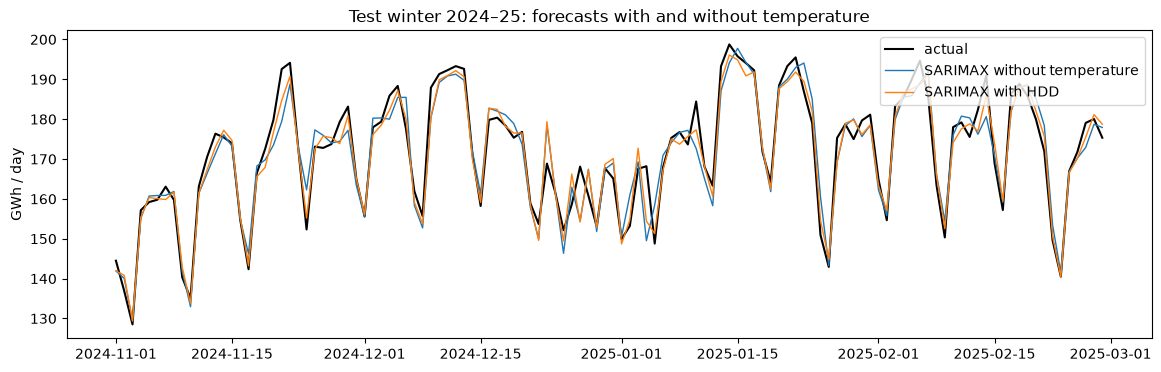

In [21]:
zoom = slice("2024-11-01", "2025-02-28")
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(test[zoom], color="black", lw=1.5, label="actual")
ax.plot(test_preds["SARIMAX + calendar + Fourier"][zoom], lw=1, label="SARIMAX without temperature")
ax.plot(test_preds["SARIMAX + calendar + Fourier + HDD"][zoom], lw=1, label="SARIMAX with HDD")
ax.set_ylabel("GWh / day"); ax.legend(loc="upper right")
ax.set_title("Test winter 2024–25: forecasts with and without temperature")
fig.savefig(FIG + "sarimax_hdd_winter_zoom.png", dpi=150, bbox_inches="tight")

## Summary – Section 5: SARIMA → SARIMAX (day-ahead)

| Model | Val 2023 MAE | Test 2024–25 MAE | Test RMSE | Test MAPE |
|---|---|---|---|---|
| SARIMA(1,0,0)(0,1,1)₇ | 3.51 | 3.93 | 5.70 | 2.77 % |
| + calendar (holidays, Christmas, bridge days) | 2.96 | 3.29 | 4.25 | 2.28 % |
| + Fourier (yearly cycle) | 2.93 | 3.17 | 4.11 | 2.19 % |
| **+ HDD (temperature)** | **2.38** | **2.51** | **3.26** | **1.75 %** |

- Order (1,0,0)(0,1,1)₇ from the ACF/PACF (lesson 18) gave the best validation error; AIC preferred richer models without forecast gain.
- Seasonal MA ≈ −0.98: fixed weekly shape + persistent level, the same structure as Holt-Winters.
- Calendar: holiday on a weekday −27.6 GWh; σ² 30.4 → 10.9.
- **Temperature cuts the test error by 21 %** (3.17 → 2.51); 1.38 GWh per HDD today + 0.31 the next day.
- With simulated forecast errors: −14 % at 1 °C, no gain at 2 °C → the benefit depends on weather-forecast quality.
- Best model: half the error of Holt-Winters (4.05), a third of seasonal naive (7.75).

In [22]:
pd.DataFrame({n: p[test.index] for n, p in test_preds.items()}).to_csv("../results/pred_07_sarimax.csv", index_label="date")